# Feature Engineering :

De données prétraitées à des variables adaptées aux deux approches d'apprentissage. **Point de départ : les données nettoyées et sauvegardées après le preprocessing.**

Deux volets sont considérés : l'apprentissage supervisé (prédiction de la température du mois suivant à partir des variables météorologiques, du mois et de l'année) et l'apprentissage non supervisé (extraction de caractéristiques à partir de la température et du rayonnement thermique pour étudier les tendances climatiques à long terme).

Ordre des étapes : création des cibles (température du mois suivant et classes Low/Medium/High) → encodage cyclique (Month Sin/Cos) → transformation SignedLog1p → RobustScaler → préparation des différents ensembles de variables → sauvegarde des données transformées.

In [20]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import RobustScaler
import os, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
#BASE    = r"D:\M2\Data Mining\DM-Weather-framework\data"
BASE = r"C:\Users\chahi\Desktop\DM-Weather-framework\data"
OUT_DIR = f"{BASE}/processed/transformed"
HEAVY = ["slhf", "e", "ro", "tp"]

In [21]:

# Chargement des datasets
train = pd.read_parquet(f"{OUT_DIR}/train_transformed.parquet")
test = pd.read_parquet(f"{OUT_DIR}/test_transformed.parquet")
df = pd.read_parquet(f"{OUT_DIR}/dataset_unsupervised.parquet")

print("Train :", train.shape)
print("Test :", test.shape)

Train : (602175, 18)
Test : (151900, 18)


In [22]:
train.head(1)

,time,latitude,longitude,t2m,d2m,sp,u10,v10,slhf,sshf,ssr,str,e,ro,tp,month,t2m_next,target_time
0,2015-01-01,18.95,3.35,16.053375,-7.532074,96317.875,-3.543621,-2.430153,-0.268765,-1886500.0,11383417.0,-9657388.0,-0.268767,0.0,0.063069,1,21.76358,2015-02-01


## **Apprentissage supervise:**

### 1. Création des variables temporelle et cyclique

In [23]:
# Puisque ta colonne month existe déjà, il suffit de créer la colonne year à partir de time.
for data in [train, test]:
    data["year"] = data["time"].dt.year

In [24]:
for data in [train, test]:

    data["month_sin"] = np.sin(
        2 * np.pi * data["month"] / 12)

    data["month_cos"] = np.cos(
        2 * np.pi * data["month"] / 12)

In [25]:
FEATURES_CYCLIC = [
    "d2m", "slhf", "ssr", "str", "sshf",
    "ro", "e", "u10", "v10", "sp", "tp","year",
    "month_sin", "month_cos"
]

TARGET = "t2m_next"

X_train = train[FEATURES_CYCLIC].copy()
y_train = train[TARGET].copy()

X_test = test[FEATURES_CYCLIC].copy()
y_test = test[TARGET].copy()

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train : (602175, 14)
y_train : (602175,)
X_test : (151900, 14)
y_test : (151900,)


### 2. Normalisation avec RobustScaler

In [26]:
from sklearn.preprocessing import RobustScaler

TO_SCALE = ["d2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp","year"]
CYCLIC   = ["month_sin","month_cos"]

scaler = RobustScaler().fit(train[TO_SCALE])

def build_X(df):
    Xs = pd.DataFrame(scaler.transform(df[TO_SCALE]), columns=TO_SCALE, index=df.index)
    return pd.concat([Xs, df[CYCLIC]], axis=1)

X_train_scaled, X_test_scaled = build_X(train), build_X(test)

### 3. division en classes:

In [27]:
import json
import os
import joblib

SUP_DIR = os.path.join(OUT_DIR, "supervised")

os.makedirs(SUP_DIR, exist_ok=True)

CLASS_LABELS = ["Low", "Medium", "High"]
inner = np.linspace(y_train.min(), y_train.max(), 4)             # 3 intervalles de largeur égale
edges = np.concatenate([[-np.inf], inner[1:-1], [np.inf]])

def to_class(y):
    return pd.cut(y, bins=edges, labels=CLASS_LABELS)

y_train_c, y_test_c = to_class(y_train), to_class(y_test)
print(inner.round(2))
print(y_train_c.value_counts(normalize=True).round(3))
print(y_test_c.value_counts(normalize=True).round(3))

json.dump({"bornes_train": inner.tolist(), "labels": CLASS_LABELS},
          open(os.path.join(SUP_DIR, "class_edges.json"), "w"), indent=2)

[ 0.28 13.86 27.44 41.03]
t2m_next
Medium    0.450
High      0.388
Low       0.162
Name: proportion, dtype: float64
t2m_next
High      0.478
Medium    0.389
Low       0.133
Name: proportion, dtype: float64


### Analyse des pourcentages des classes

,train,test
t2m_next,,
Low,16.2,13.3
Medium,45.0,38.9
High,38.8,47.8


<Axes: title={'center': 'Répartition des classes par mois (train)'}, xlabel='month'>

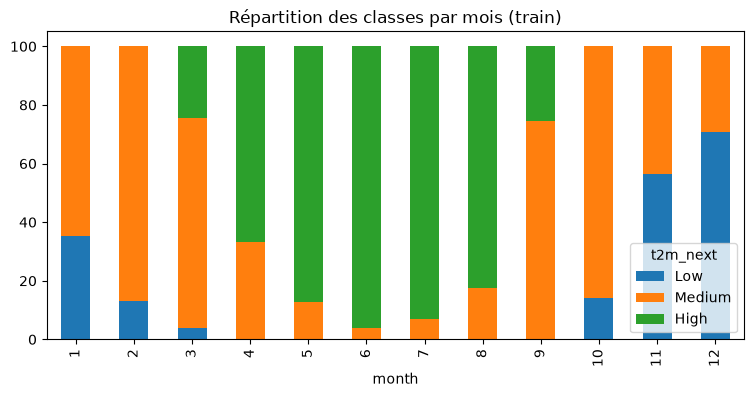

In [39]:
pct = pd.concat({
    "train": y_train_c.value_counts(normalize=True),
    "test":  y_test_c.value_counts(normalize=True),
}, axis=1).reindex(CLASS_LABELS).mul(100).round(1)
display(pct)
pct.to_csv(os.path.join(SUP_DIR, "pourcentages_classes.csv"))

# saisonnalité des classes : part de chaque classe par mois (train)
par_mois = (pd.crosstab(train["month"], y_train_c, normalize="index")[CLASS_LABELS] * 100).round(1)
par_mois.plot(kind="bar", stacked=True, figsize=(9, 4),
              title="Répartition des classes par mois (train)")

In [40]:
tm = test["month"].value_counts(normalize=True)   # poids des mois dans le test
p_cls_mois = pd.crosstab(train["month"], y_train_c, normalize="index")[CLASS_LABELS]
attendu = (p_cls_mois.mul(tm, axis=0).sum() * 100).round(1)

display(pd.DataFrame({
    "train": pct["train"],
    "test attendu (saisonnalité seule)": attendu,
    "test observé": pct["test"],
}))

,train,test attendu (saisonnalité seule),test observé
t2m_next,,,
Low,16.2,13.8,13.3
Medium,45.0,39.4,38.9
High,38.8,46.8,47.8


« Les proportions de classes diffèrent entre le train (16,2 / 45,0 / 38,8 %) et le test (13,3 / 38,9 / 47,8 %). Ce décalage s’explique presque entièrement par la composition saisonnière du test : en appliquant aux mois du test les proportions de classes observées par mois dans le train, on obtient 13,8 / 39,4 / 46,8 %, soit moins d’un point d’écart avec l’observé. Le déséquilibre du train (Medium environ 2,8 fois plus fréquente que Low) est traité par class_weight et le macro-F1. »

### 4. Sauvgarde:

In [28]:
# Préparation des datasets finaux
train_out = X_train_scaled.copy()
train_out["classe"]    = y_train_c.values
train_out["t2m_next"]  = y_train.values
train_out["month"]     = train["month"].values      # mois brut 1-12
train_out["date"]      = train["time"].values       # adapte le nom de la colonne date

test_out = X_test_scaled.copy()
test_out["classe"]    = y_test_c.values
test_out["t2m_next"]  = y_test.values
test_out["month"]     = test["month"].values
test_out["date"]      = test["time"].values

N_SAMPLE = 30_000
frac = N_SAMPLE / len(train_out)
train_sample = (train_out.groupby(["classe", "month"], observed=True)
                         .sample(frac=frac, random_state=42))

train_out.to_parquet(os.path.join(SUP_DIR, "train_supervised.parquet"), index=False)
test_out.to_parquet(os.path.join(SUP_DIR, "test_supervised.parquet"), index=False)
train_sample.to_parquet(os.path.join(SUP_DIR, "train_sample_30k.parquet"), index=False)

# Sauvegarde du scaler
joblib.dump(
    scaler,
    os.path.join(SUP_DIR, "robust_scaler.pkl")
)

# Les 4 feature sets
BASE_SUP   = ["d2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
TIME_FEATS = ["year","month_sin","month_cos"]
DROP = ["e","ro"]

FEATURE_SETS = {
    "complet":        BASE_SUP,
    "reduit":         [v for v in BASE_SUP if v not in DROP],
    "reduit_sans_sp": [v for v in BASE_SUP if v not in DROP + ["sp"]],
    "strict_cours":   [v for v in BASE_SUP if v not in DROP + ["sshf"]],
}
FEATURE_SETS = {k: v + TIME_FEATS for k, v in FEATURE_SETS.items()}
json.dump(FEATURE_SETS, open(os.path.join(SUP_DIR, "feature_sets.json"), "w"), indent=2)

print("========== SAUVEGARDE SUPERVISÉE ==========")
print("Train :", train_out.shape)
print("Test :", test_out.shape)
print("Dossier :", SUP_DIR)

========== SAUVEGARDE SUPERVISÉE ==========
Train : (602175, 18)
Test : (151900, 18)
Dossier : C:\Users\chahi\Desktop\DM-Weather-framework\data/processed/transformed\supervised


## **Apprentissage non supervise:**

In [29]:
# Regrouper les données Train et Test
df_unsup = df.copy()

# Sélectionner uniquement les variables nécessaires
df_unsup = df_unsup[
    ["time", "latitude", "longitude", "t2m", "str"]
].copy()

# Conversion de la date
df_unsup["time"] = pd.to_datetime(df_unsup["time"])

# Extraction de l'année et du mois
df_unsup["year"] = df_unsup["time"].dt.year
df_unsup["month"] = df_unsup["time"].dt.month

# Vérification
print("Dimensions :", df_unsup.shape)
print("Période :", df_unsup["time"].min(), "à", df_unsup["time"].max())

df_unsup.head()

Dimensions : (759500, 7)
Période : 2015-01-01 00:00:00 à 2026-08-01 00:00:00


,time,latitude,longitude,t2m,str,year,month
0,2015-01-01,18.95,3.35,16.053375,-9657388.0,2015,1
1,2015-02-01,18.95,3.35,21.763580,-10289442.0,2015,2
2,2015-03-01,18.95,3.35,24.019196,-10270548.0,2015,3
3,2015-04-01,18.95,3.35,27.534332,-12807040.0,2015,4
4,2015-05-01,18.95,3.35,33.414703,-12867167.0,2015,5


### 1. Vérifier les observations
Avant le pivot, vérifions que nous avons une seule observation par combinaison de date et de coordonnées.

**Absence de doublons :**
- Nombre de doublons : 0.
- Chaque combinaison time, latitude, longitude est unique.
- Nous pouvons donc utiliser pivot sans risque de rencontrer des combinaisons dupliquées.

**Régularité des observations :**
- Nombre de mois : 140.
- Nombre d'observations par mois : 5 425.
- Écart-type : 0.

Cela signifie que chaque mois possède exactement les mêmes 5 425 points géographiques. La couverture spatiale est donc constante pendant toute la période étudiée. Or, La combinaison (latitude, longitude, time) est unique, donc pivot() convient.

In [30]:
# Vérifier les doublons
n_duplicates = df_unsup.duplicated(
    subset=["time", "latitude", "longitude"]
).sum()

print("Nombre de doublons :", n_duplicates)

# Nombre d'observations par mois
monthly_counts = df_unsup.groupby("time").size()

print("\nNombre d'observations par mois :")
print(monthly_counts.describe())

Nombre de doublons : 0

Nombre d'observations par mois :
count     140.0
mean     5425.0
std         0.0
min      5425.0
25%      5425.0
50%      5425.0
75%      5425.0
max      5425.0
dtype: float64


In [31]:
# Vérifier les observations par année et par mois
monthly_year_counts = (
    df_unsup.groupby(["year", "month"])
    .size()
    .unstack(fill_value=0)
)

print(monthly_year_counts)

month    1     2     3     4     5     6     7     8     9     10    11    12
year                                                                         
2015   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2016   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2017   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2018   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2019   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2020   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2021   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2022   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2023   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2024   5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425  5425
2025   5425  5425  5425  5425  5425  5425  5425  5425  5425  542

### Transformer les données avec Pivot

In [32]:
# Transformation au format large
df_wide = df_unsup.pivot(
    index=["latitude", "longitude", "year"],
    columns="month",
    values=["t2m", "str"]
)

# Renommer les colonnes
df_wide.columns = [
    f"{var}_month_{month:02d}"
    for var, month in df_wide.columns
]

# Réinitialiser les index
df_wide = df_wide.reset_index()

df_wide.head()

,latitude,longitude,year,t2m_month_01,t2m_month_02,t2m_month_03,t2m_month_04,t2m_month_05,t2m_month_06,t2m_month_07,...,str_month_03,str_month_04,str_month_05,str_month_06,str_month_07,str_month_08,str_month_09,str_month_10,str_month_11,str_month_12
0,18.95,3.35,2015,16.053375,21.763580,24.019196,27.534332,33.414703,35.476715,34.426178,...,-10270548.0,-12807040.0,-12867167.0,-12511503.0,-9670138.0,-9527995.0,-10247684.0,-10109498.0,-9816150.0,-9350701.0
1,18.95,3.35,2016,18.776031,21.222321,24.507721,32.480621,35.356110,35.463287,34.271637,...,-11253493.0,-11530312.0,-11487663.0,-11117743.0,-10337418.0,-9838213.0,-10950351.0,-10846073.0,-9787626.0,-9044229.0
2,18.95,3.35,2017,16.230133,21.575348,26.510895,30.145905,34.917877,34.681549,34.560944,...,-11706741.0,-12207385.0,-11359854.0,-10168740.0,-10375005.0,-9834490.0,-10946946.0,-11031628.0,-10162840.0,-9069576.0
3,18.95,3.35,2018,17.994049,21.937164,26.255035,30.052643,34.361237,35.861481,34.570221,...,-12037101.0,-12616256.0,-12097719.0,-11510019.0,-10949318.0,-8719697.0,-9987941.0,-10226850.0,-9647066.0,-9640336.0
4,18.95,3.35,2019,16.611481,18.534332,25.455231,29.940338,34.126862,35.696198,35.222809,...,-10880568.0,-11696590.0,-12408240.0,-11175396.0,-10335122.0,-8164468.0,-10771665.0,-9936483.0,-9809740.0,-9916268.0


In [33]:
# Nombre de mois disponibles par année
df_wide["nb_mois"] = df_wide.drop(
    columns=["latitude", "longitude", "year"]
).notna().sum(axis=1)

print(df_wide.groupby("year")["nb_mois"].describe())

       count  mean  std   min   25%   50%   75%   max
year                                                 
2015  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2016  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2017  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2018  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2019  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2020  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2021  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2022  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2023  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2024  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2025  5425.0  24.0  0.0  24.0  24.0  24.0  24.0  24.0
2026  5425.0  16.0  0.0  16.0  16.0  16.0  16.0  16.0


L'objectif est de construire des profils annuels complets, donc c'est mieux de conserver uniquement les années 2015 à 2025 :

In [34]:
# Conserver les années complètes
df_wide_complete = df_wide[df_wide["year"] < 2026].copy()

print("Dimensions :", df_wide_complete.shape)
print("Années :", sorted(df_wide_complete["year"].unique()))
print("Valeurs manquantes :", df_wide_complete.isnull().sum().sum())

Dimensions : (59675, 28)
Années : [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Valeurs manquantes : 0


### 2. Creation des caractéristiques statistiques annuelles:

In [35]:
# Variables mensuelles
t2m_cols = [f"t2m_month_{m:02d}" for m in range(1, 13)]
str_cols = [f"str_month_{m:02d}" for m in range(1, 13)]

# Statistiques annuelles de température
df_wide_complete["t2m_mean"] = df_wide_complete[t2m_cols].mean(axis=1)
df_wide_complete["t2m_std"] = df_wide_complete[t2m_cols].std(axis=1)
df_wide_complete["t2m_min"] = df_wide_complete[t2m_cols].min(axis=1)
df_wide_complete["t2m_max"] = df_wide_complete[t2m_cols].max(axis=1)
df_wide_complete["t2m_amplitude"] = (
    df_wide_complete["t2m_max"] - df_wide_complete["t2m_min"]
)

# Statistiques annuelles de rayonnement
df_wide_complete["str_mean"] = df_wide_complete[str_cols].mean(axis=1)
df_wide_complete["str_std"] = df_wide_complete[str_cols].std(axis=1)
df_wide_complete["str_min"] = df_wide_complete[str_cols].min(axis=1)
df_wide_complete["str_max"] = df_wide_complete[str_cols].max(axis=1)
df_wide_complete["str_amplitude"] = (
    df_wide_complete["str_max"] - df_wide_complete["str_min"]
)

### 3. Anomalies et tendances climatiques (long terme)

Les statistiques annuelles décrivent le profil d'**une** année, pas son évolution. Pour capter les tendances climatiques de long terme, on ajoute, pour `t2m` et `str` :

- `*_anom` : moyenne de l'année moins la moyenne du même point sur 2015-2025 (année plus chaude ou plus froide que la normale locale) ;
- `*_trend` : pente de la régression linéaire de la moyenne annuelle sur 2015-2025 (unité par an). Elle est constante pour un même point d'une année à l'autre.

In [36]:
years = np.sort(df_wide_complete["year"].unique())
xc = (years - years.mean()).astype(float)

for v in ["t2m", "str"]:
    # matrice points x années des moyennes annuelles
    M = (df_wide_complete
         .pivot(index=["latitude", "longitude"], columns="year", values=f"{v}_mean")
         .sort_index(axis=1))

    # pente par point (unité / an), régression linéaire sur les années
    slope = (M.values - M.values.mean(axis=1, keepdims=True)) @ xc / (xc ** 2).sum()
    trend = pd.Series(slope, index=M.index, name=f"{v}_trend").reset_index()
    df_wide_complete = df_wide_complete.merge(trend, on=["latitude", "longitude"], how="left")

    # anomalie : moyenne de l'année - moyenne du point sur toutes les années
    df_wide_complete[f"{v}_anom"] = (
        df_wide_complete[f"{v}_mean"]
        - df_wide_complete.groupby(["latitude", "longitude"])[f"{v}_mean"].transform("mean")
    )

print(df_wide_complete[["t2m_anom", "t2m_trend", "str_anom", "str_trend"]].describe().round(4))
print("Valeurs manquantes :", df_wide_complete[["t2m_anom", "t2m_trend", "str_anom", "str_trend"]].isnull().sum().sum())

         t2m_anom   t2m_trend      str_anom   str_trend
count  59675.0000  59675.0000  5.967500e+04  59675.0000
mean      -0.0000      0.1071  0.000000e+00 -20057.0521
std        0.5465      0.0295  1.779409e+05  10669.1138
min       -1.7341      0.0306 -5.140802e+05 -67711.0591
25%       -0.4456      0.0878 -1.397090e+05 -23736.9727
50%        0.0544      0.1029  1.505186e+04 -17625.6909
75%        0.3987      0.1188  1.119244e+05 -13397.0636
max        1.2237      0.2113  1.039955e+06   2021.5545
Valeurs manquantes : 0


### 4. Choix des variables de clustering et standardisation

- `latitude`, `longitude`, `year` et `nb_mois` sont **exclus** des variables de clustering : les coordonnées servent uniquement à cartographier les clusters, l'année à les suivre dans le temps, et `nb_mois` est constant (24).
- `t2m` (°C) et `str` (≈ -10⁷) n'ont pas la même échelle : on standardise (StandardScaler).
- Le scaler est ajusté sur **toutes les années ensemble** pour que les clusters de 2015 et de 2025 restent comparables.

In [37]:
from sklearn.preprocessing import StandardScaler

META = ["latitude", "longitude", "year"]
STATS_COLS = ["t2m_mean", "t2m_std", "t2m_min", "t2m_max", "t2m_amplitude",
              "str_mean", "str_std", "str_min", "str_max", "str_amplitude"]
TREND_COLS = ["t2m_anom", "str_anom", "t2m_trend", "str_trend"]

CLUSTER_FEATURES = t2m_cols + str_cols + STATS_COLS + TREND_COLS   # 38 colonnes

scaler_u = StandardScaler().fit(df_wide_complete[CLUSTER_FEATURES])
X_u = pd.DataFrame(
    scaler_u.transform(df_wide_complete[CLUSTER_FEATURES]),
    columns=CLUSTER_FEATURES,
    index=df_wide_complete.index
)
unsup = pd.concat([df_wide_complete[META], X_u], axis=1)

print("Nombre de variables de clustering :", len(CLUSTER_FEATURES))
print("Dimensions :", unsup.shape)
print("Moyenne max (en valeur absolue) :", X_u.mean().abs().max().round(6))
print("Écart-type min / max :", X_u.std().min().round(4), "/", X_u.std().max().round(4))
print("Valeurs manquantes :", unsup.isnull().sum().sum())

Nombre de variables de clustering : 38
Dimensions : (59675, 41)
Moyenne max (en valeur absolue) : 0.0
Écart-type min / max : 1.0 / 1.0
Valeurs manquantes : 0


### 5. Sauvegarde des données non supervisées

In [38]:
import os, json, joblib

UNSUP_DIR = os.path.join(OUT_DIR, "unsupervised")
os.makedirs(UNSUP_DIR, exist_ok=True)

unsup.to_parquet(os.path.join(UNSUP_DIR, "unsupervised_scaled.parquet"), index=False)
joblib.dump(scaler_u, os.path.join(UNSUP_DIR, "standard_scaler.pkl"))
json.dump(CLUSTER_FEATURES, open(os.path.join(UNSUP_DIR, "cluster_features.json"), "w"), indent=2)

print("========== SAUVEGARDE NON SUPERVISÉE ==========")
print("Données :", unsup.shape)
print("Dossier :", UNSUP_DIR)

========== SAUVEGARDE NON SUPERVISÉE ==========
Données : (59675, 41)
Dossier : C:\Users\chahi\Desktop\DM-Weather-framework\data/processed/transformed\unsupervised
